# 6. Complex analysis fundamentals

## 6.1 Motivation

In smooth quadrature, we saw that many of the error bounds depended on some high derivative of the function to be integrated. For example, 
1. the (simple, not composite) trapezoidal rule had 
$$ \left|\int_a^b f(x) \mathrm{d} x - \frac{b-a}{2}[f(a) + f(b)]\right| \leq \frac{1}{12} ||f''||_{L_{\infty}}(b-a)^3. $$
2. Gauss--Legendre quadrature (with $n+1$ nodes indexed from $0$ to $n$) has
$$\left|\int_a^b f(x) \mathrm{d} x - \frac{b-a}{2}[f(a) + f(b)]\right| \sim \frac{f^{(2n+2)}}{(2n+2)!}.$$

The right-hand-sides above are reminiscent of terms in a Taylor expansion, e.g. consider the Taylor expansion of $f(z)$ around $z = 0$, 
$$
f(z) = \sum_{n=0}^{\infty} a_n z^n,
$$
$$
a_n = \frac{f^{(n)}(0)}{n!}.
$$
To estimate the error in quadrature (and interpolation), we therefore need to know how large these Taylor series terms can get. 
To list a few applications of numerical integration (quadrature) in the sciences, take the following examples:

### 6.1.1 KL divergence

For probability distributions $p$ and $q$, the KL divergence is defined as 
$$
D_{\mathrm{KL}}(P\,\|\,Q)
= \int_{-\infty}^{\infty}
p(x)\log\!\left(\frac{p(x)}{q(x)}\right)\,dx.
$$
The KL divergence is a measure of how similar the two distributions look like. It is therefore helpful in applications where the objective is to produce (predict) a value with as similar of a probability distribution as some given goal. This function occurs frequently in Bayesian neural networks, or inference, and contains an integral over smooth functions -- a prime candidate for evaluation by quadrature.

### 6.1.2 Bayesian evidence

On the topic of Bayesian inference, the quantity appearing in the denominator in Bayes' theorem is the Bayesian evidence,
$$
p(D) = \int p(D\mid\theta)\,p(\theta)\,d\theta,
$$
where $p(D\mid\theta)$ is a function describing the probability of obtaining/observing data $D$ given a model parameterized by the parameter(s) $\theta$, and $p(\theta)$ summarizes the prior constraints/knowledge of the model parameters. $p(D\mid\theta)$ is called the likelihood, and the above integral is therefore also referred to as the marginalized likelihood (since the model parameters have been integrated out/marginalized over). The Bayesian evidence is used to compare scientific models, since it captures both
- how likely a model is to produce the data we observed (the more likely, the better), and
- how many parameters it uses to do so (the fewer, the better, as per Occam's razor).
It takes the form of an integral, but even if the integrand is closed-form, the integral itself rarely is. It therefore needs to be computed via quadrature, though not necessarily with the methods we discuss in this course.

### 6.1.3 Convolution

In Fourier space, a product of functions $f$ and $g$ becomes a convolution, defined as
$$
(f*g)(t)
= \int_{-\infty}^{\infty} f(t)\,g(t-\tau)\,d\tau.
$$
Convolutions occur in physics, e.g. when computing a diffraction pattern, in signal processing, and in neural networks specializing in image recognition (e.g. convolutional neural nets). It is once again extremely rare for a convolution to be computable on paper, which means that one has to resort to quadrature.

## 6.2 Analyticity, radius of convergence

```{admonition} Definition: analyticity
If $f$ is analytic at $0$, there exists $\xi>0$ such that the above series **converges absolutely** for all $z$ in the disc
$$
|z|<\xi,
$$
and diverges absolutely for all $z$ outside.
```

Analyticity necessarily implies smoothness, i.e. the function has derivatives of all orders, but not the other way round. Some examples of analyticity (or lack thereof) include:
- polynomials, $e^z$, and trigonometric functions are analytic everywhere (thus they are "entire"),
- $|z|$ is not analytic at $z=0$,
- piecewise functions are not analytic where intervals meet.

The above definition used the concept of **absolute convergence**, which in turn is defined as follows.

```{admonition} Definition: Absolute convergence
A real or complex series
$$
\sum_{n=0}^{\infty} a_n
$$
converges **absolutely** if
$$
\sum_{n=0}^{\infty} |a_n| = L
$$
for some real and finite $L$.
```

Some functions we'll have to deal with will be analytic everywhere, except at specific points, for example **isolated singularities**. These are a finite number of points at which the Taylor series of the function fails to converge, and the function "blows up". For example, the function
$$
f(z) = \frac{1}{1+z^2}
$$
has two isolated singularities at $ z=\pm i,$ around which is has no convergent Taylor series. These points are so-called simple poles, or poles of order 1. If we try to Taylor-expand the function around $z = 0$, we see that its radius of convergence is determined by the distance to the nearest singularities, and will in this case be $1$. Take a look at this function in the complex plane:

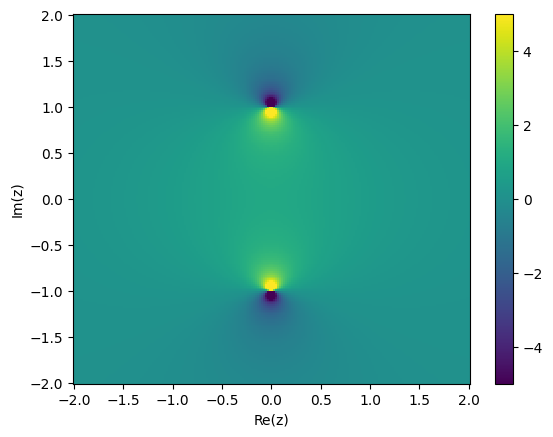

In [13]:
import matplotlib.pyplot as plt
import numpy as np

axisarr = np.linspace(-2, 2, 200)
rearr, imarr = np.meshgrid(axisarr, axisarr)
z = rearr + 1j*imarr
f = lambda z: 1/(1+z**2)

plt.figure()
plt.pcolormesh(rearr, imarr, np.real(f(z)), vmin = -5, vmax = 5)
plt.colorbar()
plt.xlabel("Re(z)")
plt.ylabel("Im(z)")
plt.show()

This radius of convergence tells us something about the size of terms in the Taylor series of the function. Take a function, expanded around the point $z = 0$, at which is it analytic. Suppose its radius of convergence around $x_0$ is $\rho$. Within this radius of convergence, i.e. for $|z| = \rho - \varepsilon$ $\forall \varepsilon > 0$, it is true that 
$$
|a_n|(\xi-\varepsilon)^n \leq C,
$$
since the function is absolutely convergent. Then,
$$
|a_n| \leq \frac{C}{(\xi-\varepsilon)^n},
$$
i.e. the larger the radius of convergence, the smaller this upper bound on the Taylor coefficients. This, in turn, determines the error of smooth quadratures, or interpolation, involving this function. 

## 6.3 Radius of convergence and interpolation/quadrature error

For example, assume we want to interpolate a function $f$ on the interval $[a,b]$. Let's say we know that $f$ is analytic in an open domain containing the "stadium"
$$
\left\{z\in\mathbb{C}: \operatorname{dist}(z,[a,b])\leq R\right\},
$$
i.e. inside of an ellipse that is a distance $R$ away from the interval.
Then, based on the above, the Taylor coefficients for $f$ satisfy
$$
|a_n| \leq \frac{C}{R^n}.
$$
Recalling our theorem on the accuracy of interpolation, we know that if $L_nf$ is the interpolating polynomial of $f$ we constructed using $n+1$ nodes, the error in interpolation will be
$$ 
||f - L_nf||_{L_\infty} = \max_{x \in [a,b]} |f(x) - L_nf(x)|  \leq \frac{f^{(n+1)}(\xi)}{(n+1)!}(b-a)^{n+1}, \quad \xi \in [a,b].
$$
Identifying the derivative term as a Taylor coefficient, we can say that
$$ 
||f - L_nf||_{L_\infty} \leq \frac{c'}{R^{n+1}}(b-a)^{n+1} = c'\left(\frac{H}{R}\right)^{n+1},
$$
where $H = b-a $ is the width of the interpolation interval. We can deduce that
- if the radius of convergence (often distance to nearest singularity) is **larger** than the width of the interval, then interpolation will converge with $n$, and it will do so exponentially,
- the exact rate of convergence depends on the ratio of the radius of convergence and the interval width, with the larger, the quicker the convergence,
- if the radius of convergence is **smaller** than or equal to the interval width, interpolation may not converge.